# 2. Customer segmentation

Who are the customers, which ones matter most, and which ones are slipping away?

Each customer is described by three things: days since their last order, how many orders they have placed, and how much they have spent. This is the standard recency, frequency and spend approach. Customers are scored 1 to 5 on recency and on frequency, and the two scores place them in one of six named segments.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from shoplens.clean import SHOPS, load, clean, open_shop
from shoplens.segmentation import GROUPS

plt.style.use("dark_background")
plt.rcParams.update({"figure.facecolor": "black", "axes.facecolor": "black", "axes.edgecolor": "#3a3b3e", "axes.grid": True,
                     "grid.color": "#1c1c1e", "figure.figsize": (11, 4.5), "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
WHITE, SILVER, GREY, JADE, RED = "#f2f2f0", "#d4d6da", "#8d8d90", "#5fd0a0", "#e0787a"
COLORS = dict(zip(GROUPS, [JADE, "#9fd9bd", WHITE, SILVER, "#c9a25a", GREY]))
money = lambda v, _=None: f"£{v:,.0f}"
UK, AMAZON, GROCERY = SHOPS

sales, removed = open_shop(UK)
from shoplens.segmentation import summarize, scores, group, by_group, profile, repeat_buying

customers = summarize(sales)
customers["group"] = group(customers)

## The six segments

In [2]:
table = by_group(customers)
table.style.format({"customers": "{:,.0f}", "spend": "£{:,.0f}", "typical_orders": "{:.0f}", "typical_days_since": "{:.0f}", "share_of_customers": "{:.0%}", "share_of_spend": "{:.0%}"})

,customers,spend,typical_orders,typical_days_since,share_of_customers,share_of_spend
group,,,,,,
Best customers,"1,115","£5,662,089",7,10,26%,68%
Regulars,825,"£1,148,602",3,37,19%,14%
New,234,"£80,716",1,18,5%,1%
Occasional,420,"£206,768",1,49,10%,2%
Going quiet,654,"£732,613",3,132,15%,9%
Lost,"1,076","£442,066",1,218,25%,5%


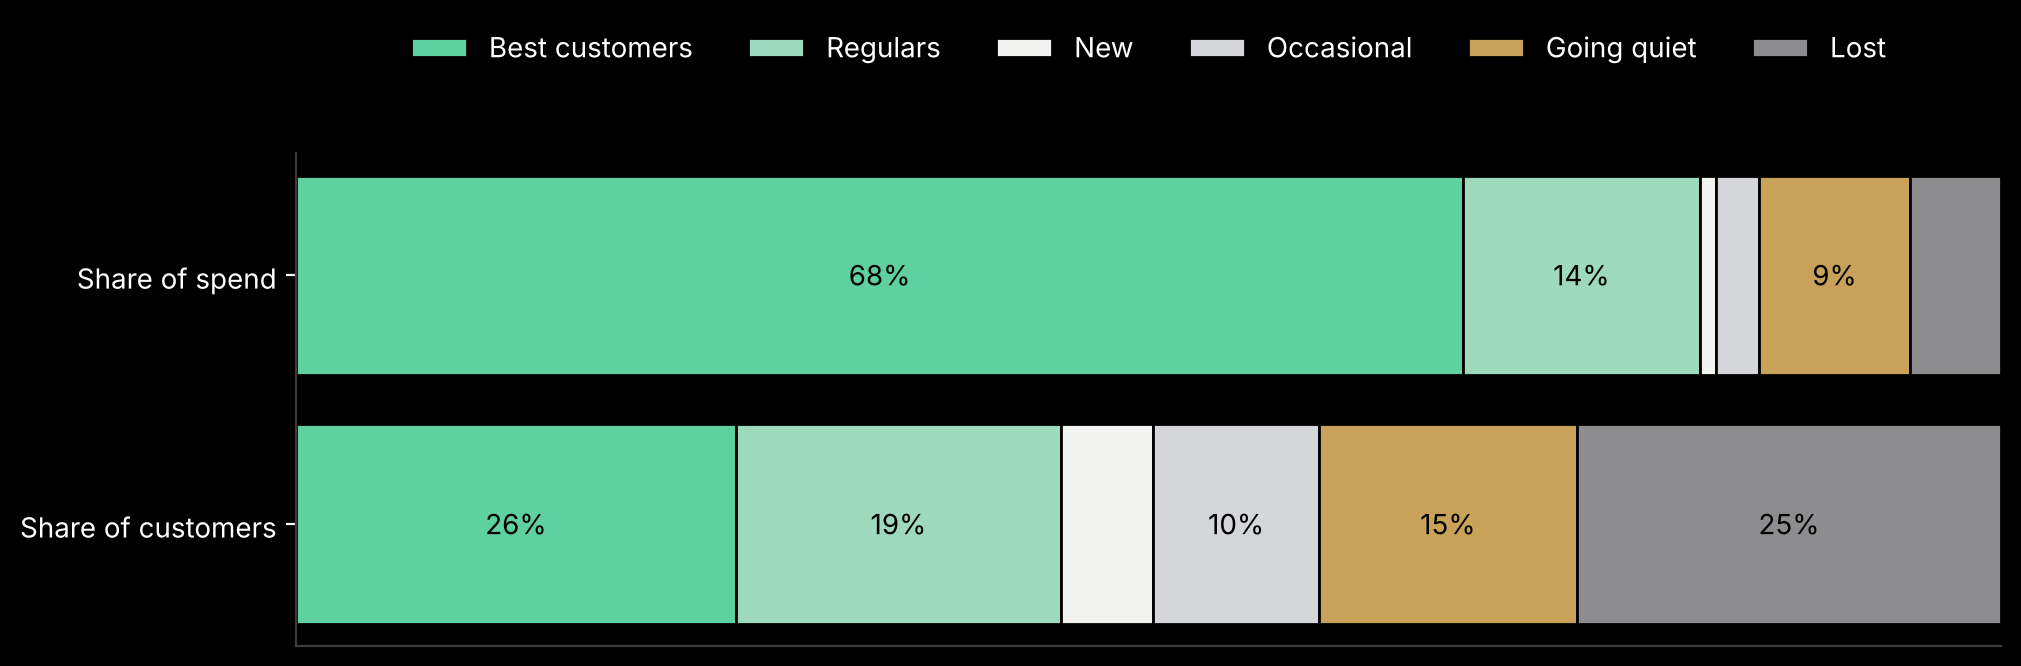

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.2))
for row, column in enumerate(["share_of_customers", "share_of_spend"]):
    left = 0
    for name in table.index:
        ax.barh(row, table.loc[name, column], left=left, color=COLORS[name], edgecolor="black", label=name if row == 0 else None)
        if table.loc[name, column] > 0.06:
            ax.text(left + table.loc[name, column] / 2, row, f"{table.loc[name, column]:.0%}", ha="center", va="center", color="black", fontsize=10)
        left += table.loc[name, column]
ax.set_yticks([0, 1], ["Share of customers", "Share of spend"]); ax.set_xlim(0, 1); ax.xaxis.set_visible(False); ax.grid(False)
ax.legend(frameon=False, ncol=6, loc="upper center", bbox_to_anchor=(0.5, 1.3))
plt.show()

A quarter of the customers bring in more than two thirds of the money.

## How the segments are drawn

Every customer sits in one square of this grid. The number is how many customers are in the square and the color is the segment it belongs to. New is the one exception to the grid: a single order, placed recently.

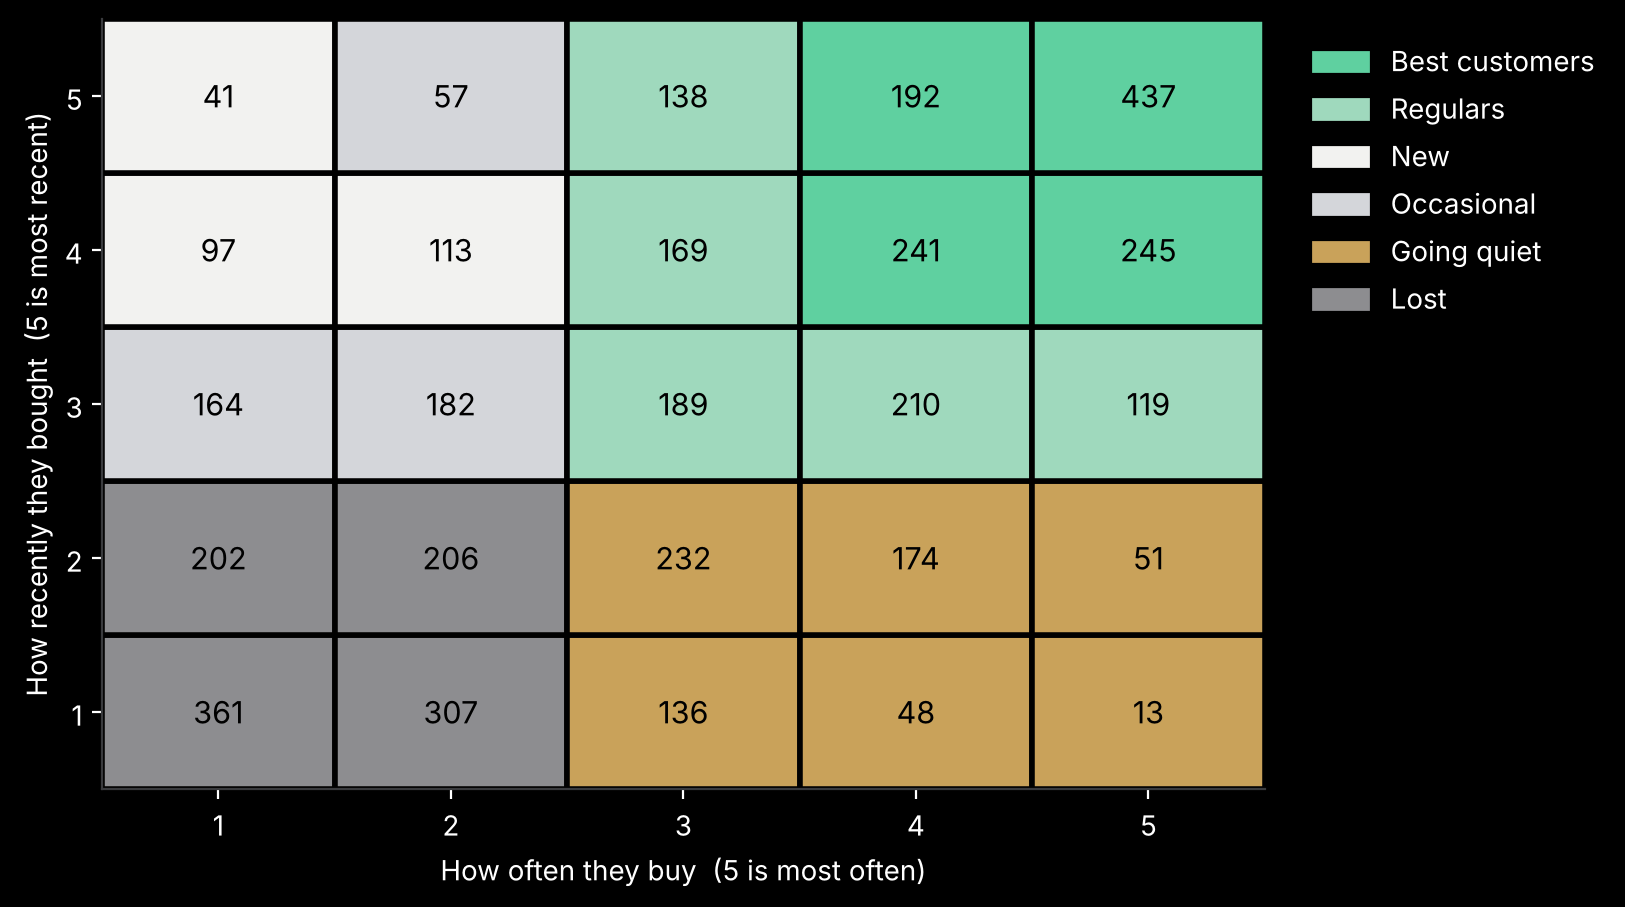

In [4]:
recent, often = scores(customers)
grid = pd.crosstab(recent, often)
owner = customers.groupby([recent, often])["group"].agg(lambda g: g.mode()[0]).unstack()
fig, ax = plt.subplots(figsize=(7.5, 5))
for r in grid.index:
    for f in grid.columns:
        ax.add_patch(plt.Rectangle((f - 0.5, r - 0.5), 1, 1, color=COLORS[owner.loc[r, f]], ec="black", lw=2))
        ax.text(f, r, f"{grid.loc[r, f]:,}", ha="center", va="center", color="black", fontsize=11)
ax.set_xlim(0.5, 5.5); ax.set_ylim(0.5, 5.5); ax.grid(False)
ax.set_xlabel("How often they buy  (5 is most often)"); ax.set_ylabel("How recently they bought  (5 is most recent)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLORS[g]) for g in GROUPS], labels=GROUPS, frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

## Every customer

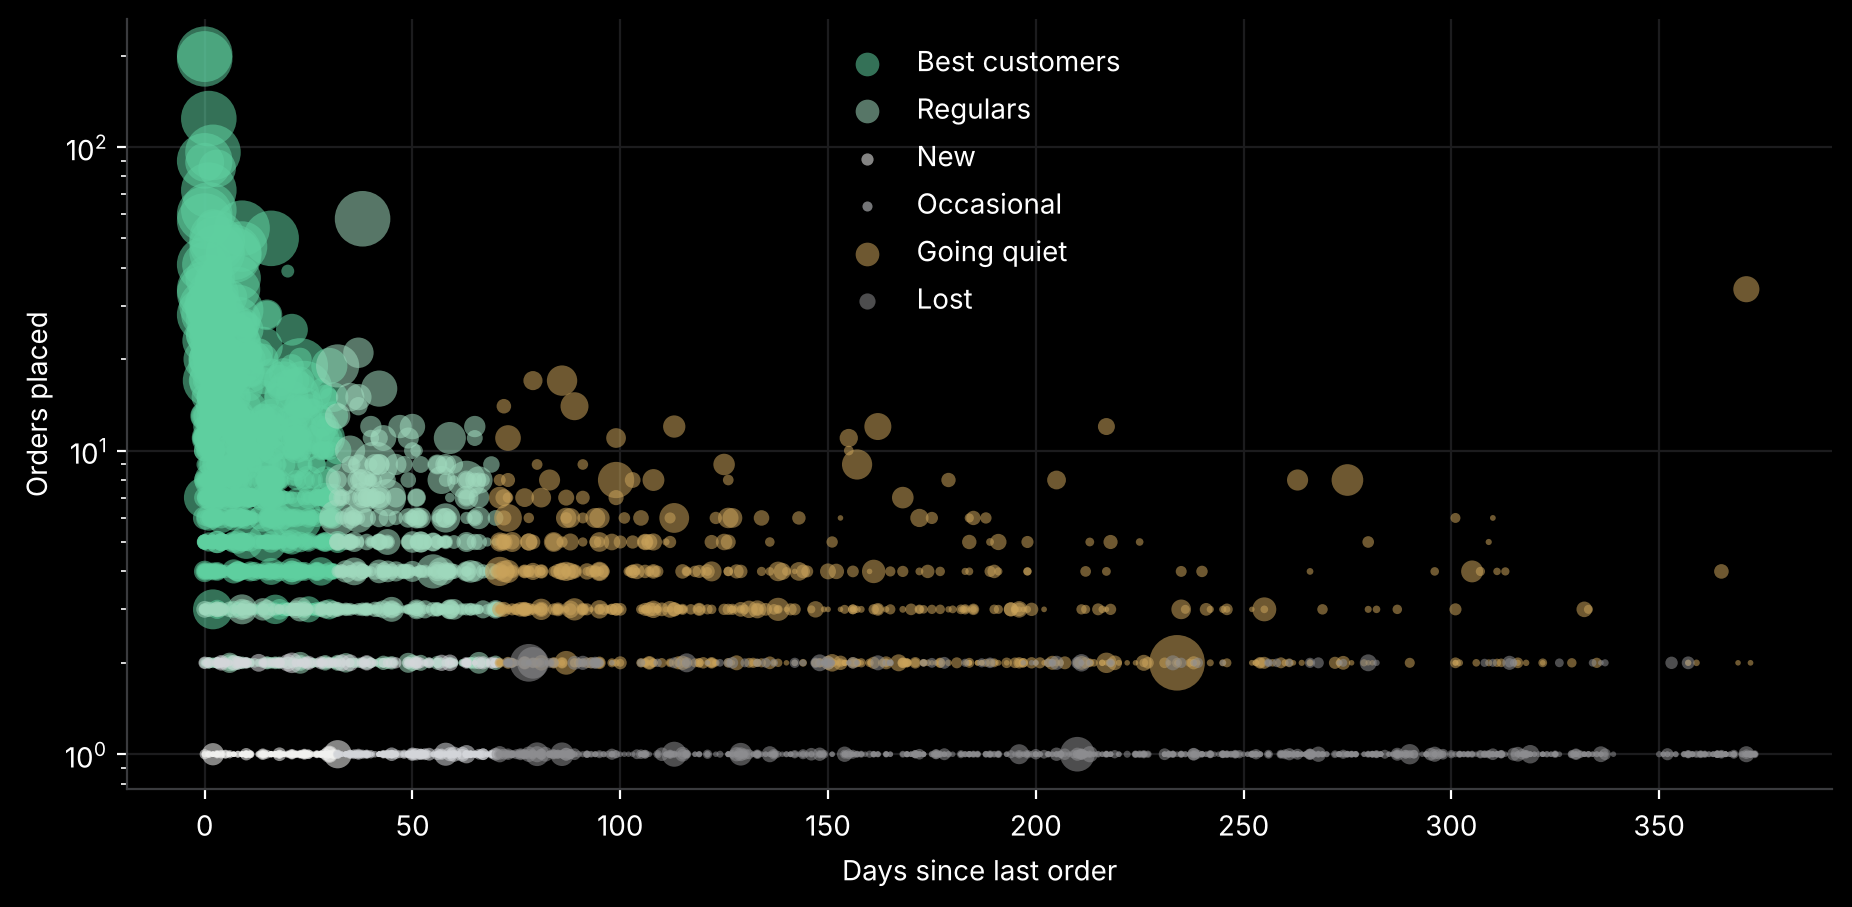

In [5]:
fig, ax = plt.subplots(figsize=(11, 5))
for name in GROUPS:
    part = customers[customers.group == name]
    ax.scatter(part.days_since, part.orders, s=np.clip(part.spend / 60, 4, 400), color=COLORS[name], alpha=0.55, linewidths=0, label=name)
ax.set_yscale("log"); ax.set_xlabel("Days since last order"); ax.set_ylabel("Orders placed"); ax.legend(frameon=False, markerscale=0.6)
plt.show()

Each dot is a customer and its size is their spend.

## How each segment shops, and what to do about it

**Leans toward** lists the products a segment spends a bigger share on than customers as a whole.

In [6]:
profile(sales, customers).style.format({"average_order": "£{:,.0f}", "products_per_order": "{:.0f}", "orders_per_customer": "{:.1f}"})

,average_order,products_per_order,orders_per_customer,leans_toward,what_to_do
group,,,,,
Best customers,£510,21,10.0,"Vintage Union Jack Memoboard, Black Heart Card Holder, Popcorn Holder","Keep them. Early access, a thank you, no discounts they do not need."
Regulars,£383,22,3.6,"Feltcraft Cushion Rabbit, Grow A Flytrap Or Sunflower In Tin, Feltcraft Cushion Owl",Grow them. Suggest the products their group buys together.
New,£345,26,1.0,"Metal Sign Take It Or Leave It, Baking Set Spaceboy Design, White Skull Hot Water Bottle",Win the second order. A follow up within a few weeks of the first.
Occasional,£380,25,1.3,"Hand Warmer Union Jack, Christmas Lights 10 Reindeer, Love Hot Water Bottle",Low effort. Include in seasonal mailings.
Going quiet,£331,17,3.4,"Fairy Cake Flannel Assorted Colour, Set/4 White Retro Storage Cubes, Doormat Fairy Cake",Contact now. They were good customers and half can still be won back.
Lost,£375,19,1.1,"Small Popcorn Holder, Round Snack Boxes Set Of 4 Fruits, Assorted Colours Silk Fan","Do not spend much. One last offer, then stop."


## Going quiet: the list to act on

People who ordered several times and have not been back in months.

In [7]:
quiet = customers[customers.group == "Going quiet"].nlargest(10, "spend")[["orders", "spend", "days_since"]]
quiet.style.format({"spend": "£{:,.0f}", "orders": "{:.0f}", "days_since": "{:.0f}"})

,orders,spend,days_since
customer,,,
15749,2,"£24,851",234
16180,8,"£10,227",99
13093,8,"£7,798",275
16745,17,"£7,171",86
12980,9,"£7,092",157
13027,6,"£6,912",113
16182,4,"£6,618",71
15939,14,"£6,087",89
14101,6,"£5,977",73


## Do customers come back?

Each row is the set of customers who placed their first order in that month. Each column is a later month. The number is the share of them who ordered again.

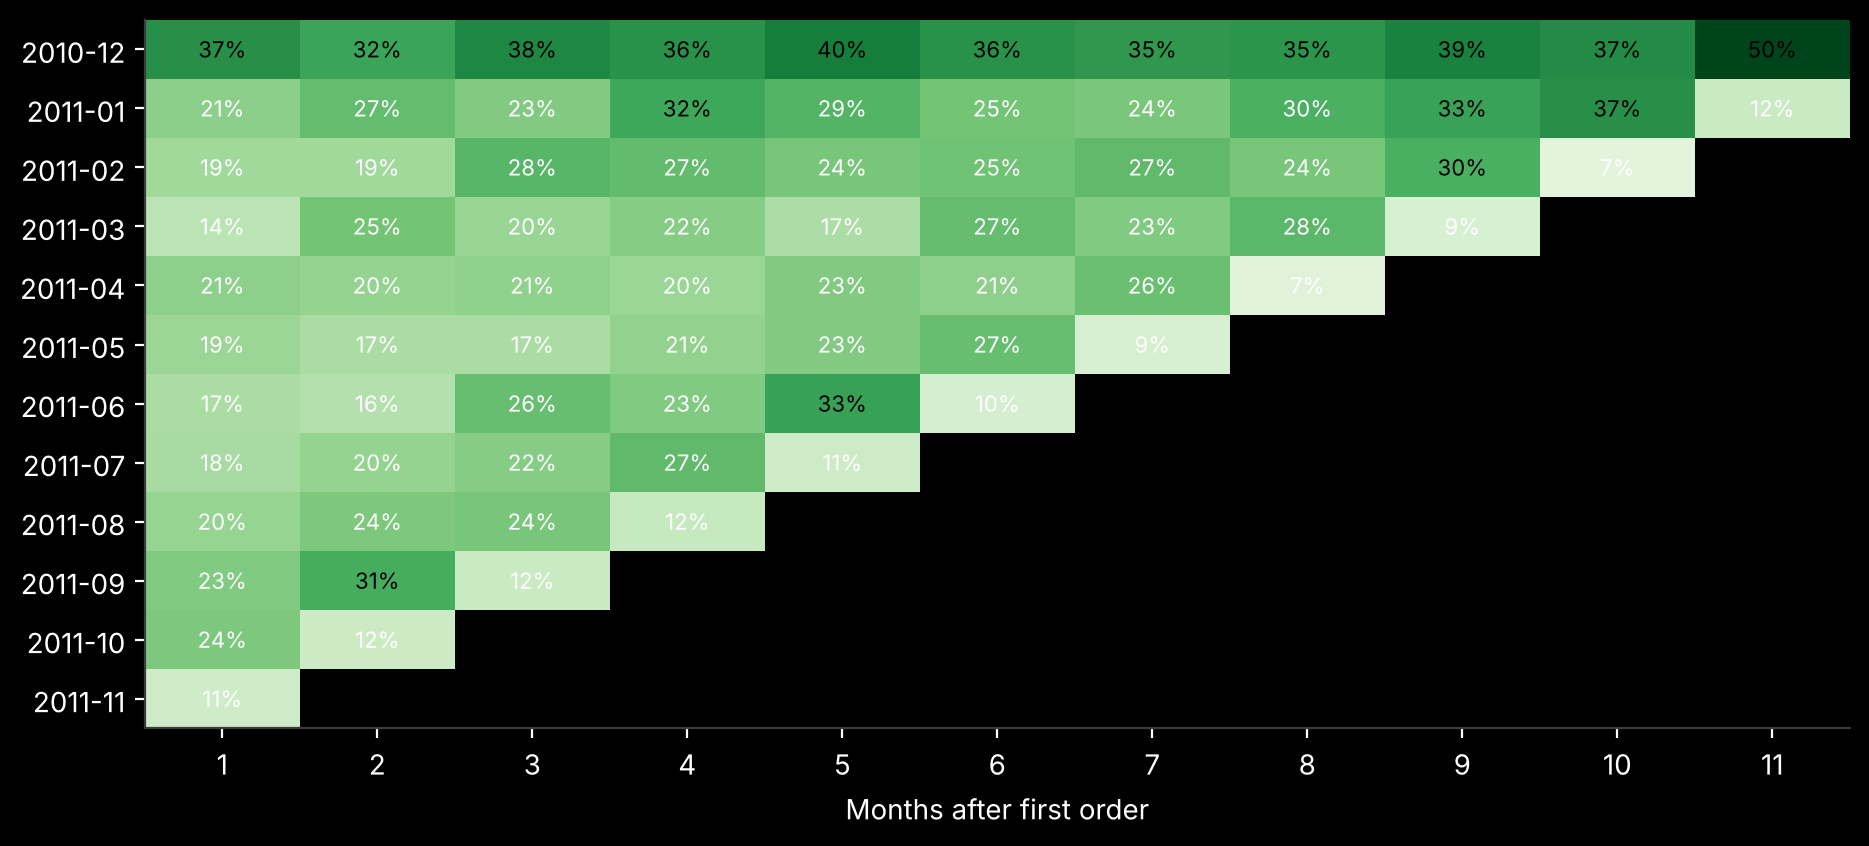

In [8]:
back = repeat_buying(sales).iloc[:-1, 1:12]
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.imshow(back.to_numpy(float), cmap="Greens", vmin=0, vmax=0.5, aspect="auto")
ax.set_xticks(range(back.shape[1]), back.columns); ax.set_yticks(range(len(back)), [str(m) for m in back.index]); ax.grid(False)
ax.set_xlabel("Months after first order")
for (i, j), v in np.ndenumerate(back.to_numpy(float)):
    if not np.isnan(v):
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", color="white" if v < 0.3 else "black", fontsize=8)
plt.show()

Customers who first bought in December 2010 kept returning at 30 to 50 percent a month. Later groups return at about half that rate. The earliest group likely includes long standing customers whose history starts before the data does.

## Named segments or clustering?

The first version of this project used k means clustering. So here is a fair contest. Both methods see only the sales before the last 90 days, and both make six segments. Then the last 90 days show how well each one sorted customers.

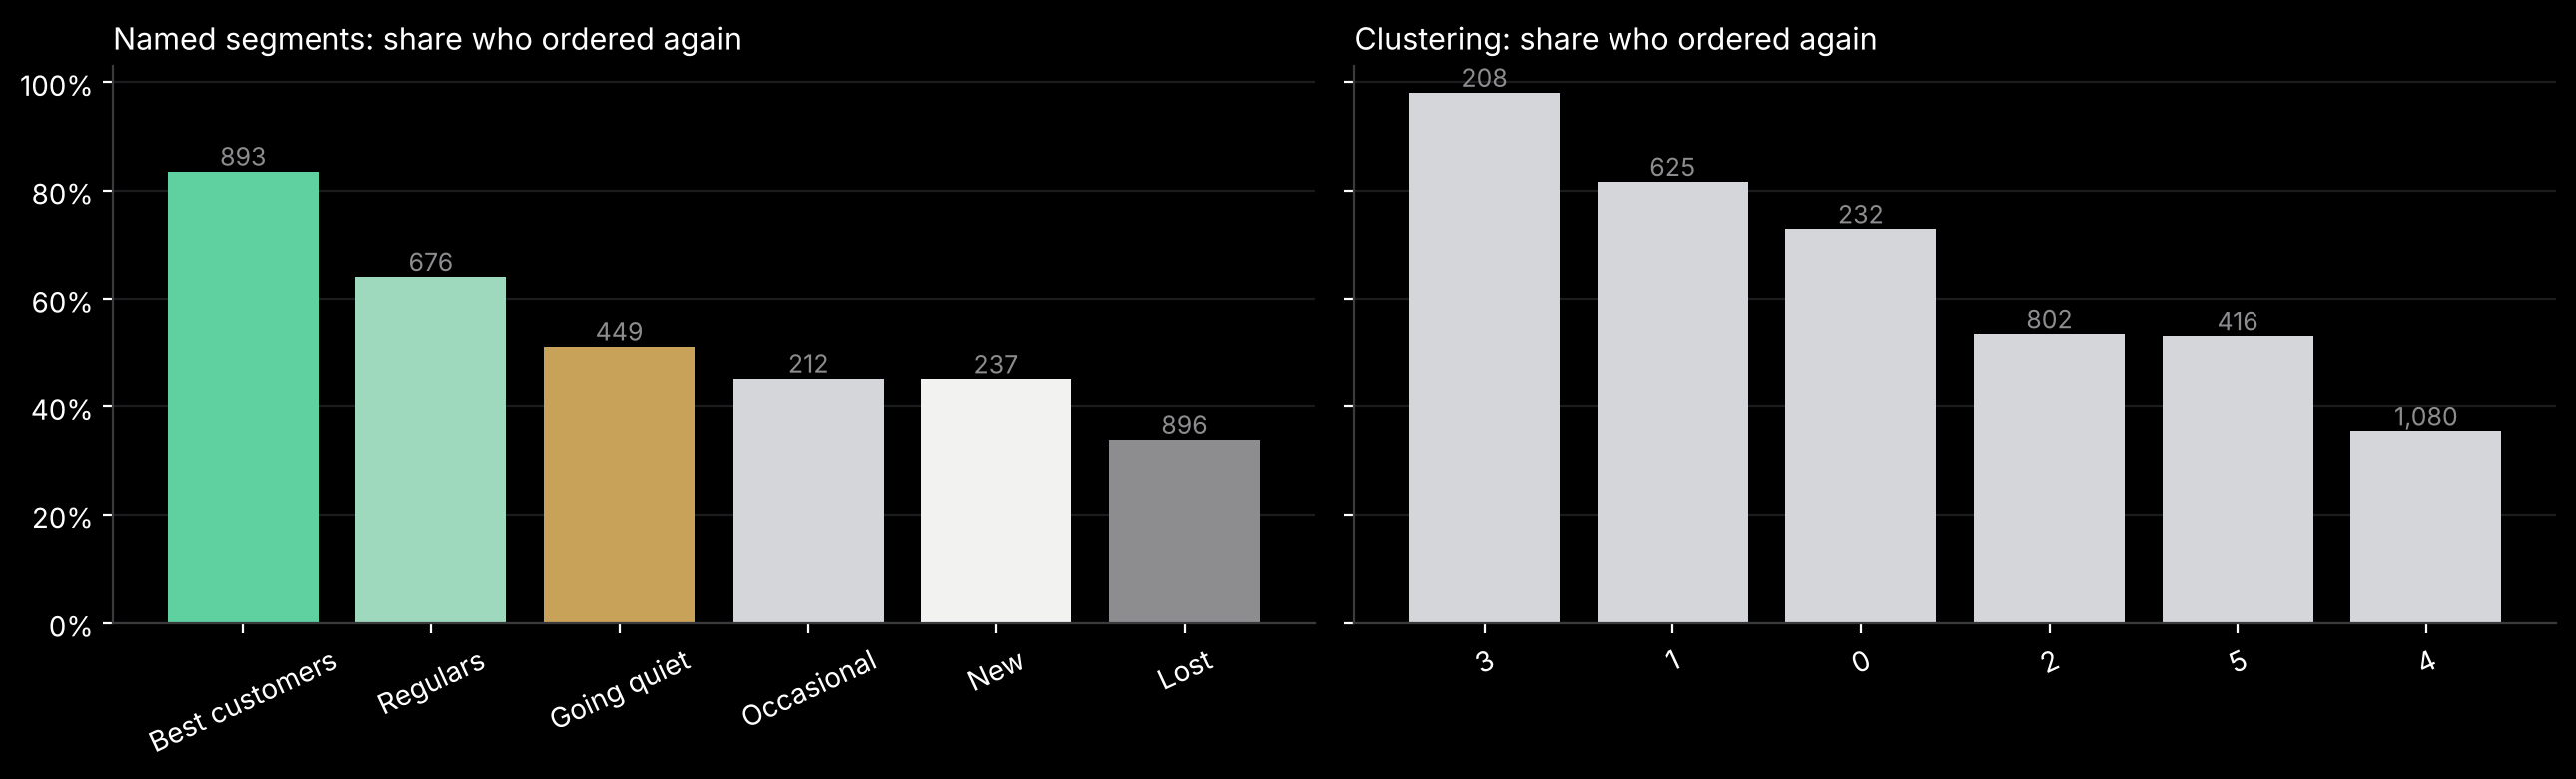

,Named segments,Clustering
Who came back,15%,16%
What they spent,4%,12%


In [9]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from shoplens.forward import split

before, after, cutoff = split(sales)
then = summarize(before, cutoff)
then["Named segments"] = group(then)
measures = StandardScaler().fit_transform(np.log1p(then[["days_since", "orders", "spend"]]))
then["Clustering"] = KMeans(6, n_init=10, random_state=0).fit_predict(measures)
spend_after = after.groupby("customer")["revenue"].sum()
then["came_back"] = then.index.isin(spend_after.index)
then["spend_after"] = spend_after.reindex(then.index).fillna(0)

def explained(method, outcome):
    """The share of the differences between customers that the segments account for. 0 is none, 1 is all."""
    return 1 - then.groupby(method)[outcome].transform(lambda v: (v - v.mean()) ** 2).sum() / ((then[outcome] - then[outcome].mean()) ** 2).sum()

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, method in zip(axes, ["Named segments", "Clustering"]):
    rate = then.groupby(method).agg(came_back=("came_back", "mean"), customers=("came_back", "size")).sort_values("came_back", ascending=False)
    bars = ax.bar([str(i) for i in rate.index], rate.came_back, color=[COLORS.get(i, SILVER) for i in rate.index])
    ax.bar_label(bars, [f"{n:,}" for n in rate.customers], color=GREY, fontsize=9)
    ax.set_title(f"{method}: share who ordered again", loc="left", fontsize=11); ax.tick_params(axis="x", rotation=25); ax.grid(axis="x", visible=False)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout(); plt.show()
pd.DataFrame({m: {"Who came back": explained(m, "came_back"), "What they spent": explained(m, "spend_after")} for m in ["Named segments", "Clustering"]}).style.format("{:.0%}")

In [10]:
then.groupby("Clustering").agg(customers=("spend", "size"), days_since=("days_since", "median"), orders=("orders", "median"), spend=("spend", "median"), came_back=("came_back", "mean"), spend_after=("spend_after", "mean")).sort_values("came_back", ascending=False).style.format({"spend": "£{:,.0f}", "spend_after": "£{:,.0f}", "came_back": "{:.0%}", "days_since": "{:.0f}", "orders": "{:.0f}"})

,customers,days_since,orders,spend,came_back,spend_after
Clustering,,,,,,
3,208,8,14,"£5,337",98%,"£5,912"
1,625,36,5,"£1,674",82%,£900
0,232,3,4,"£1,103",73%,£801
2,802,105,2,£679,53%,£393
5,416,24,1,£344,53%,£272
4,1080,169,1,£204,35%,£157


The numbers over the bars are customers in each segment.

Clustering did a little better at sorting who came back, and clearly better on what they spent. The reason is in the table: it found a small top cluster of about 200 customers who nearly all returned and spent several times more than anyone else. The named segments fold those into Best customers, because they score on recency and frequency and leave spend out.

The named segments are still the ones the app uses. Each has a rule anyone can read, the same name means the same thing next month, and they hold up on later sales. But the contest shows where they fall short: a shop with a few very large buyers should look at spend inside its Best customers.

## What this says

* **A quarter of customers are worth two thirds of the revenue.** Keeping them matters more than anything else here.
* **About 650 customers are going quiet.** They have ordered several times and spent real money. That list is where a shop would start.
* **Each segment has a clear next step**, from protecting the best customers to winning a second order from new ones.
* **Clustering found one thing the rules missed:** a small group of very large buyers inside Best customers.